## 1. Setup

In [1]:
from __future__ import annotations
import sys, subprocess
from pathlib import Path

PROJECT_ROOT = Path().resolve().parents[1]
W4_SRC  = PROJECT_ROOT / "workshops" / "w4" / "src"
W1_ROOT = PROJECT_ROOT / "workshops" / "w1"
for _p in (str(W4_SRC), str(W1_ROOT)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from constants import CHECKPOINTS_DIR, RUNS_DIR, FIGURES_DIR, SEED
from autoencoder.data_loader import load_w1_data
from train.train_ae  import load_checkpoint as ae_load_checkpoint, set_seed
from train.train_vae import load_checkpoint as vae_load_checkpoint
from analize_latent.analyze_latent import LatentExtractor, LatentProjector, SeparabilityAnalyzer

LATENT_DIR = RUNS_DIR / "latent"
LATENT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

device: cpu


## 2. Data & stratified samples

In [2]:
df, y_all, _, _, _, split = load_w1_data()

_, _, prep, _, _ = ae_load_checkpoint(CHECKPOINTS_DIR / "ae_best.pt", DEVICE)

test_idx = split["test"]
df_test  = df.iloc[test_idx].reset_index(drop=True)
y_test   = y_all[test_idx]

# Stratified 20k sample (natural churn prevalence ~9%)
rng      = np.random.default_rng(SEED)
n_sample = 20_000
classes, counts = np.unique(y_test, return_counts=True)
sub_idx_list = []
for cls, cnt in zip(classes, counts):
    cls_rows = np.where(y_test == cls)[0]
    n_draw   = max(1, int(round(n_sample * cnt / len(y_test))))
    sub_idx_list.append(rng.choice(cls_rows, size=min(n_draw, len(cls_rows)), replace=False))
sub_idx = np.concatenate(sub_idx_list)

sample_df = pd.DataFrame({
    "w1_row":   test_idx[sub_idx],
    "msno":     df_test["msno"].iloc[sub_idx].values,
    "is_churn": y_test[sub_idx],
})
sample_df.to_csv(LATENT_DIR / "latent_sample.csv", index=False)
print(f"20k sample  churn={sample_df['is_churn'].mean():.3%}")

# Balanced sample: 5k normal + 5k churn
rng2     = np.random.default_rng(SEED + 1)
idx_n    = sub_idx[y_test[sub_idx] == 0]
idx_c    = sub_idx[y_test[sub_idx] == 1]
bal_n    = rng2.choice(idx_n, size=min(5_000, len(idx_n)), replace=False)
bal_c    = rng2.choice(idx_c, size=min(5_000, len(idx_c)), replace=False)
bal_idx  = np.concatenate([bal_n, bal_c])
bal_df   = pd.DataFrame({
    "w1_row":   test_idx[bal_idx],
    "msno":     df_test["msno"].iloc[bal_idx].values,
    "is_churn": y_test[bal_idx],
})
bal_df.to_csv(LATENT_DIR / "latent_sample_balanced.csv", index=False)
print(f"Balanced sample  {len(bal_df):,}  churn={bal_df['is_churn'].mean():.3%}")

x_num_sub, x_cat_sub = prep.transform(df_test.iloc[sub_idx].reset_index(drop=True))
x_num_bal, x_cat_bal = prep.transform(df_test.iloc[bal_idx].reset_index(drop=True))
y_sub = y_test[sub_idx]
y_bal = y_test[bal_idx]

train_feb rows:   992,931 | label month: 2017-02 | churn rate: 0.0639
test      rows:   970,960 | label month: 2017-03 | churn rate: 0.0899
labelled cohorts: (1963891, 63) | users in both labelled months: 881701
20k sample  churn=8.995%
Balanced sample  6,799  churn=26.460%


## 3. AE and VAE latent representations

In [3]:
ae_model,  _, _, _, _ = ae_load_checkpoint( CHECKPOINTS_DIR / "ae_best.pt",  DEVICE)
vae_model, _, _, _, _ = vae_load_checkpoint(CHECKPOINTS_DIR / "vae_best.pt", DEVICE)

extractor = LatentExtractor(ae_model, vae_model, prep, DEVICE)

ae_z   = extractor.ae_latent( x_num_sub, x_cat_sub)   # (20k, 16)
vae_mu = extractor.vae_latent(x_num_sub, x_cat_sub)   # (20k, 16)

np.savez(LATENT_DIR / "ae_latent.npz",  z=ae_z,   is_churn=y_sub)
np.savez(LATENT_DIR / "vae_latent.npz", mu=vae_mu, is_churn=y_sub)

ae_z_bal   = extractor.ae_latent( x_num_bal, x_cat_bal)
vae_mu_bal = extractor.vae_latent(x_num_bal, x_cat_bal)

active_mask = extractor.vae_active_dims(vae_mu)
print(f"AE latent  shape: {ae_z.shape}")
print(f"VAE mu     shape: {vae_mu.shape}   active dims: {active_mask.sum()}/{len(active_mask)}")

AE latent  shape: (20000, 16)
VAE mu     shape: (20000, 16)   active dims: 13/16


## 4. LSTM latent (subprocess)

Runs in a separate process so W2 imports don't collide with W1/W4.
**Requires** `workshops/w2/export-sequential-v5` to be present locally.

In [4]:
W2_ROOT      = PROJECT_ROOT / "workshops" / "w2"
SCRIPT       = W4_SRC / "analize_latent" / "extract_lstm_latent.py"
SAMPLE_CSV   = LATENT_DIR / "latent_sample.csv"
LSTM_NPZ_OUT = LATENT_DIR / "lstm_latent.npz"

export_dir = W2_ROOT / "export-sequential-v5"
if not export_dir.exists():
    print(f"WARNING: {export_dir} not found — skipping LSTM extraction.")
    print("Place the W2 sequential export there and re-run this cell.")
    lstm_available = False
else:
    result = subprocess.run(
        [sys.executable, str(SCRIPT),
         "--sample", str(SAMPLE_CSV),
         "--out",    str(LSTM_NPZ_OUT),
         "--device", str(DEVICE)],
        cwd=str(W2_ROOT),
        capture_output=True, text=True,
    )
    print(result.stdout)
    if result.returncode != 0:
        print("STDERR:", result.stderr)
        lstm_available = False
    else:
        lstm_available = True

Place the W2 sequential export there and re-run this cell.


In [5]:
# Load and align by msno
if lstm_available:
    npz = np.load(LSTM_NPZ_OUT, allow_pickle=True)
    lstm_msno    = npz["msno"]
    lstm_latent  = npz["latent"].astype(np.float32)
    lstm_churn   = npz["is_churn"].astype(int)

    # Reorder to match sample_df order
    msno_to_idx = {m: i for i, m in enumerate(lstm_msno)}
    order       = np.array([msno_to_idx[m] for m in sample_df["msno"].values])
    lstm_latent  = lstm_latent[order]
    lstm_churn   = lstm_churn[order]

    assert np.array_equal(lstm_churn, y_sub), "Label mismatch between sample and LSTM output"
    print(f"LSTM latent aligned  shape={lstm_latent.shape}  churn={lstm_churn.mean():.3%}")

    lstm_latent_bal = lstm_latent[np.isin(sub_idx, bal_idx)]
    # simpler: recompute balanced using same indices
    lstm_latent_bal = lstm_latent[np.where(np.isin(sub_idx, bal_idx))[0]]
else:
    lstm_latent = lstm_latent_bal = None
    print("LSTM latents unavailable — steps 6-7 will skip the LSTM.")

LSTM latents unavailable — steps 6-7 will skip the LSTM.


## 5. Latent statistics: AE vs VAE

=== AE latent stats (first 8 dims) ===
 dim    mean    std
   0 -7.3468 4.6390
   1 -1.3831 2.9784
   2  7.4605 2.9574
   3 -7.5356 2.6893
   4  1.3908 4.2864
   5 -2.5400 4.3844
   6 -0.8717 4.4848
   7  1.4602 4.2974

=== VAE latent stats (first 8 dims) ===
 dim    mean    std
   0 -0.0752 0.7748
   1  0.0108 0.8852
   2  0.0229 0.0145
   3 -0.0074 0.0139
   4  0.0735 0.9256
   5  0.0763 1.0263
   6  0.1807 0.7158
   7  0.0085 0.6350


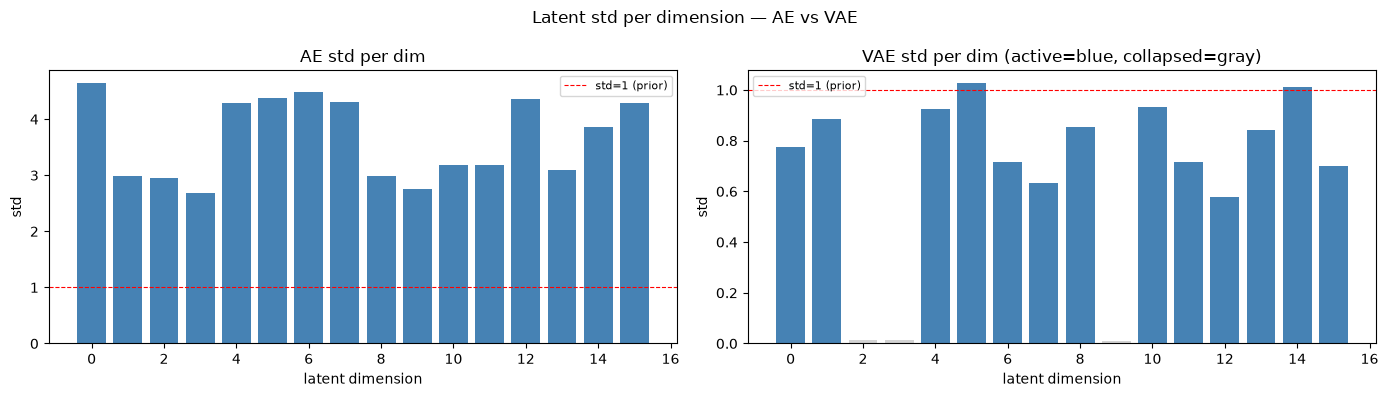

In [6]:
analyzer = SeparabilityAnalyzer(seed=SEED)

ae_stats  = analyzer.latent_stats(ae_z)
vae_stats = analyzer.latent_stats(vae_mu)

print("=== AE latent stats (first 8 dims) ===")
print(ae_stats.head(8).to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\n=== VAE latent stats (first 8 dims) ===")
print(vae_stats.head(8).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, stats, title in zip(
    axes,
    [ae_stats, vae_stats],
    ["AE std per dim", "VAE std per dim (active=blue, collapsed=gray)"],
):
    colors = "steelblue"
    if "VAE" in title:
        colors = np.where(active_mask, "steelblue", "lightgray")
    ax.bar(stats["dim"], stats["std"], color=colors)
    ax.axhline(1.0, linestyle="--", color="red", linewidth=0.8, label="std=1 (prior)")
    ax.set_xlabel("latent dimension"); ax.set_ylabel("std"); ax.set_title(title)
    ax.legend(fontsize=8)

plt.suptitle("Latent std per dimension — AE vs VAE", fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "latent_dim_stats.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Separability metrics

In [7]:
sep_rows = []

for name, lat in [
    ("AE (all dims)",            ae_z),
    ("VAE (all dims)",           vae_mu),
    ("VAE (active dims only)",   vae_mu[:, active_mask]),
]:
    sil     = analyzer.silhouette(lat, y_sub)
    sil_std = analyzer.silhouette_standardized(lat, y_sub)
    auc     = analyzer.linear_probe_auc(lat, y_sub)
    sep_rows.append({
        "model":                  name,
        "latent_dim":             lat.shape[1],
        "silhouette":             sil,
        "silhouette_standardized": sil_std,
        "linear_probe_auc":       auc,
    })

if lstm_latent is not None:
    sil     = analyzer.silhouette(lstm_latent, y_sub)
    sil_std = analyzer.silhouette_standardized(lstm_latent, y_sub)
    auc     = analyzer.linear_probe_auc(lstm_latent, y_sub)
    sep_rows.append({
        "model":                  "LSTM (supervised)",
        "latent_dim":             lstm_latent.shape[1],
        "silhouette":             sil,
        "silhouette_standardized": sil_std,
        "linear_probe_auc":       auc,
    })

sep_df = pd.DataFrame(sep_rows)
sep_df.to_csv(LATENT_DIR / "latent_separability.csv", index=False)
print(sep_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

                 model  latent_dim  silhouette  silhouette_standardized  linear_probe_auc
         AE (all dims)          16      0.2536                   0.2515            0.8480
        VAE (all dims)          16      0.1620                   0.1558            0.8468
VAE (active dims only)          13      0.1620                   0.1521            0.8458


## 7. t-SNE and UMAP projections (balanced sample)

In [9]:
projector = LatentProjector(seed=SEED)

models_bal = {"AE": ae_z_bal, "VAE": vae_mu_bal}
if lstm_latent_bal is not None:
    models_bal["LSTM"] = lstm_latent_bal

tsne_projs = {name: projector.tsne(lat) for name, lat in models_bal.items()}
umap_projs = {name: projector.umap(lat) for name, lat in models_bal.items()}

c:\Users\Usuario\Desktop\Materias\ML\Final Project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Usuario\Desktop\Materias\ML\Final Project\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\Usuario\Desktop\Materias\ML\Final Project\env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


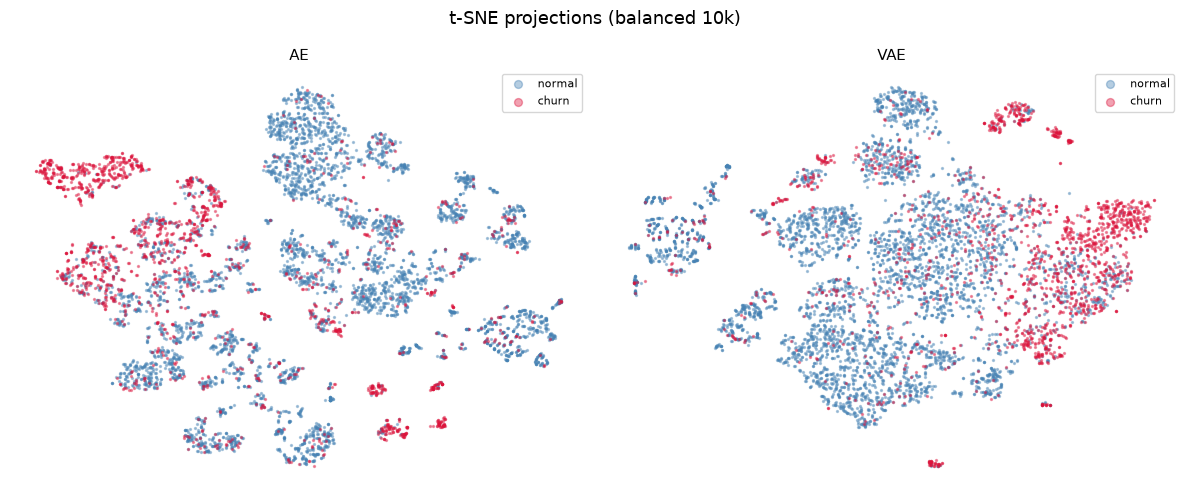

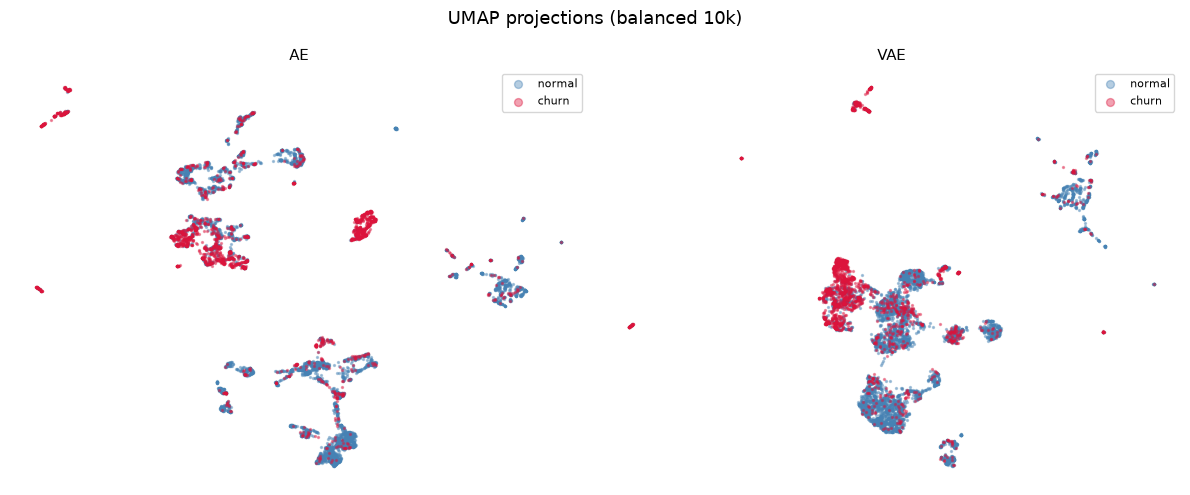

In [10]:
def plot_projections(projs, y, title_prefix, fname):
    n_models = len(projs)
    fig, axes = plt.subplots(1, n_models, figsize=(6 * n_models, 5))
    if n_models == 1:
        axes = [axes]
    colors = {0: "steelblue", 1: "crimson"}
    labels = {0: "normal", 1: "churn"}
    for ax, (name, proj) in zip(axes, projs.items()):
        for cls in [0, 1]:   # draw normal first, churn on top
            mask = y_bal == cls
            ax.scatter(proj[mask, 0], proj[mask, 1],
                       s=2, alpha=0.4, color=colors[cls], label=labels[cls], rasterized=True)
        ax.set_title(name, fontsize=11)
        ax.axis("off")
        ax.legend(markerscale=4, fontsize=8)
    plt.suptitle(title_prefix, fontsize=13)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()

plot_projections(tsne_projs, y_bal, "t-SNE projections (balanced 10k)", "latent_tsne.png")
plot_projections(umap_projs, y_bal, "UMAP projections (balanced 10k)", "latent_umap.png")

## 8. UMAP of VAE coloured by anomaly score (optional)

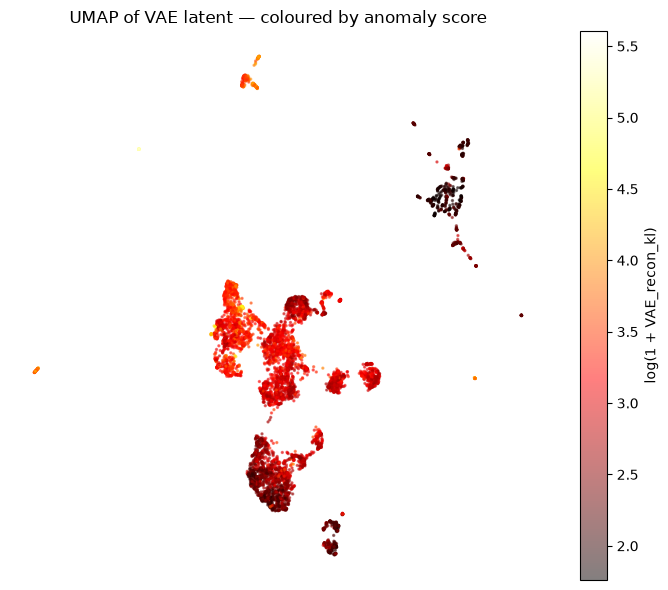

In [11]:
from evaluate.anomaly_detection import AnomalyConfig, AnomalyScorer
from train.train_ae import load_checkpoint as _ae_lc

_ae_m, _, _, _, _ = _ae_lc(CHECKPOINTS_DIR / "ae_best.pt", DEVICE)
_cfg    = AnomalyConfig()
_scorer = AnomalyScorer(_ae_m, vae_model, DEVICE, _cfg)

x_num_b2, x_cat_b2 = prep.transform(df_test.iloc[bal_idx].reset_index(drop=True))
_scores = _scorer.scores(x_num_b2, x_cat_b2)
vae_score_bal = _scores["VAE_recon_kl"]

umap_vae = umap_projs.get("VAE")
if umap_vae is not None:
    fig, ax = plt.subplots(figsize=(7, 6))
    sc = ax.scatter(umap_vae[:, 0], umap_vae[:, 1],
                    c=np.log1p(vae_score_bal), cmap="hot", s=2, alpha=0.5, rasterized=True)
    plt.colorbar(sc, ax=ax, label="log(1 + VAE_recon_kl)")
    ax.set_title("UMAP of VAE latent — coloured by anomaly score")
    ax.axis("off")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "latent_umap_vae_anomaly.png", dpi=150, bbox_inches="tight")
    plt.show()

## 9. Summary

In [12]:
print("=== Latent separability ranking ===")
ranked = sep_df.sort_values("linear_probe_auc", ascending=False)
print(ranked[["model", "latent_dim", "silhouette_standardized", "linear_probe_auc"]].to_string(
    index=False, float_format=lambda x: f"{x:.4f}"
))

if lstm_latent is not None:
    lstm_auc = sep_df[sep_df["model"] == "LSTM (supervised)"]["linear_probe_auc"].iloc[0]
    best_unsup = sep_df[sep_df["model"] != "LSTM (supervised)"]["linear_probe_auc"].max()
    best_name  = sep_df.loc[sep_df["linear_probe_auc"].idxmax(), "model"]
    print(f"\nLSTM linear_probe_auc : {lstm_auc:.4f}")
    print(f"Best unsupervised      : {best_unsup:.4f}  ({best_name})")
    print(f"Supervised advantage   : {lstm_auc - best_unsup:+.4f}")

vae_all   = sep_df[sep_df["model"] == "VAE (all dims)"]["silhouette_standardized"].iloc[0]
vae_act   = sep_df[sep_df["model"] == "VAE (active dims only)"]["silhouette_standardized"].iloc[0]
print(f"\nVAE active dims improve silhouette: {vae_act > vae_all}  ({vae_all:.4f} -> {vae_act:.4f})")

=== Latent separability ranking ===
                 model  latent_dim  silhouette_standardized  linear_probe_auc
         AE (all dims)          16                   0.2515            0.8480
        VAE (all dims)          16                   0.1558            0.8468
VAE (active dims only)          13                   0.1521            0.8458

VAE active dims improve silhouette: False  (0.1558 -> 0.1521)
